In [3]:
import pandas as pd

df = pd.read_csv("housing.csv")

X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

# individuiamo eventuali dati mancanti

print(X.isna().mean() * 100)

# l'unico valore mancante è in total_bedrooms
# effettuiamo imputazione ed encoding delle feature categoriche

# lo split richiesto è 80/5/15
from sklearn.model_selection import train_test_split

X_train, temp1, y_train, temp2 = train_test_split(X,y, test_size=0.20, random_state=42)

val_size = 0.05 / 0.20 #percentuale desiderata fratto percentuale su cui si lavora

X_test,X_val,y_test,y_val = train_test_split(temp1,temp2, train_size=val_size)

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

cat_features = X_train.select_dtypes(include=["bool", "string", "object"]).columns
num_features = X_train.select_dtypes(include=["number"]).columns

cat_pipeline = Pipeline(steps = [
    ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore")),
    
])

num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers =[
    ("cat", cat_pipeline, cat_features),
    ("num", num_pipeline, num_features)
])

preprocessor.set_output(transform="pandas")

preprocessor.fit(X_train, y_train)

X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)
X_val_processed = preprocessor.transform(X_val)





longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
total_bedrooms        1.002907
population            0.000000
households            0.000000
median_income         0.000000
ocean_proximity       0.000000
dtype: float64


In [4]:
print(X_train_processed.isna().mean() * 100)

from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Lasso

lasso = Lasso(random_state=42, alpha=1000, max_iter=1000)
select = SelectFromModel(estimator=lasso, max_features=10)

X_train_sel = select.fit_transform(X_train_processed, y_train)
X_test_sel = select.transform(X_test_processed)
X_val_sel = select.transform(X_val_processed)



cat__ocean_proximity_<1H OCEAN     0.0
cat__ocean_proximity_INLAND        0.0
cat__ocean_proximity_ISLAND        0.0
cat__ocean_proximity_NEAR BAY      0.0
cat__ocean_proximity_NEAR OCEAN    0.0
num__longitude                     0.0
num__latitude                      0.0
num__housing_median_age            0.0
num__total_rooms                   0.0
num__total_bedrooms                0.0
num__population                    0.0
num__households                    0.0
num__median_income                 0.0
dtype: float64


In [5]:
# regressione lasso

from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV, KFold

ridge = Ridge(random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

param_grid_ridge = {
    "alpha" : [0.1,1,10,100,1000]
}

grid = GridSearchCV(param_grid=param_grid_ridge,estimator=ridge, cv=cv, scoring="neg_root_mean_squared_error")

grid.fit(X_train_sel, y_train)
best_estimator_ridge = grid.best_estimator_
best_params_ridge = grid.best_params_
best_score_ridge = grid.best_score_

print(f"Miglior modello: {best_estimator_ridge}")
print(f"Miglior score in cv: {best_score_ridge}")
print(f"Migliori parametri: {best_params_ridge}")

ridge_test_pred = best_estimator_ridge.predict(X_test_sel)
ridge_train_pred = best_estimator_ridge.predict(X_train_sel)



Miglior modello: Ridge(alpha=1, random_state=42)
Miglior score in cv: -68618.98464511607
Migliori parametri: {'alpha': 1}


In [6]:
# regressione lasso

from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold

lasso = Lasso(random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

param_grid_lasso = {
    "alpha" : [0.1,1,10,100,1000],
    "max_iter" : [500,1000,1500]
}

grid = GridSearchCV(param_grid=param_grid_lasso,estimator=lasso, cv=cv, scoring="neg_root_mean_squared_error")

grid.fit(X_train_sel, y_train)
best_estimator_lasso = grid.best_estimator_
best_params_lasso = grid.best_params_
best_score_lasso = grid.best_score_

print(f"Miglior modello: {best_estimator_lasso}")
print(f"Miglior score in cv: {best_score_lasso}")
print(f"Migliori parametri: {best_params_lasso}")

lasso_test_pred = best_estimator_lasso.predict(X_test_sel)
lasso_train_pred = best_estimator_lasso.predict(X_train_sel)




/opt/anaconda3/envs/bigdata/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.923e+11, tolerance: 1.751e+10
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/envs/bigdata/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.578e+12, tolerance: 1.769e+10
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/envs/bigdata/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regula

Miglior modello: Lasso(alpha=0.1, max_iter=500, random_state=42)
Miglior score in cv: -68618.9872687826
Migliori parametri: {'alpha': 0.1, 'max_iter': 500}


/opt/anaconda3/envs/bigdata/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.789e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [7]:
from sklearn.metrics import root_mean_squared_error, r2_score

rmse_ridge_train = root_mean_squared_error(y_train, ridge_train_pred)
rmse_ridge_test = root_mean_squared_error(y_test, ridge_test_pred)

rmse_lasso_train = root_mean_squared_error(y_train, lasso_train_pred)
rmse_lasso_test = root_mean_squared_error(y_test, lasso_test_pred)

r2_lasso_train = r2_score(y_train, lasso_train_pred)
r2_lasso_test = r2_score(y_test, lasso_test_pred)

r2_ridge_train = r2_score(y_train, ridge_train_pred)
r2_ridge_test = r2_score(y_test, ridge_test_pred)

Epoch    1: 100%|██████████| 258/258 [00:00<00:00, 463.51it/s]


Train loss: 21097101284.2171
Validation loss: 11354019829.5510
Test loss: 10393742396.2353 Accuracy:   0.00
Metrics:



Epoch    2: 100%|██████████| 258/258 [00:00<00:00, 909.50it/s]


Train loss: 12572685278.2636
Validation loss: 8746571723.7551
Test loss: 8208182181.6471 Accuracy:   0.00
Metrics:



Epoch    3: 100%|██████████| 258/258 [00:00<00:00, 913.48it/s]


Train loss: 10490457280.4961
Validation loss: 8169369714.9388
Test loss: 7473660160.0000 Accuracy:   0.00
Metrics:



... (76 outputs left out)

Epoch   42: 100%|██████████| 258/258 [00:00<00:00, 806.08it/s]


Train loss: 6801062768.1240
Validation loss: 7065481012.2449
Test loss: 7079765579.2941 Accuracy:   0.00
Metrics:



Epoch   43: 100%|██████████| 258/258 [00:00<00:00, 922.25it/s]


Train loss: 6766761182.2636
Validation loss: 5713606729.1429
Test loss: 5653055759.0588 Accuracy:   0.00
Metrics:



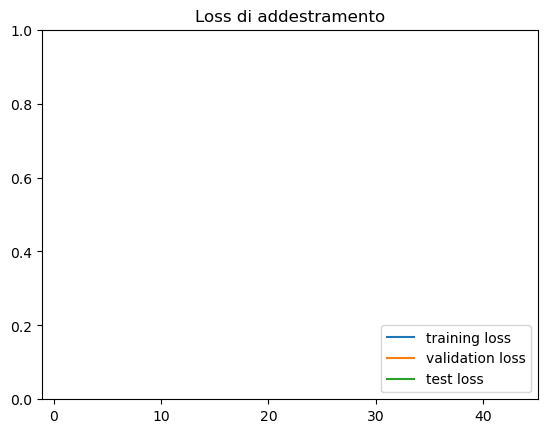

In [8]:
import torch
import torchnn as tnn
import numpy as np

from torch import nn
from torch.utils.data import DataLoader, Dataset

# regressione, sia X che y devono avere dtype=torch.float32



class HousingData(Dataset):
    def __init__(self,X,y):
        self.X = torch.tensor(np.array(X), dtype=torch.float32)
        self.y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

train_data = HousingData(X_train_sel, y_train)
val_data = HousingData(X_val_sel, y_val)
test_data = HousingData(X_test_sel, y_test)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

input_dim = X_train_sel.shape[1]

class HouseNet(nn.Module):
    def __init__(self, input_dim=input_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, out_features=128),
            nn.ReLU(),

            nn.Linear(128,64),
            nn.Dropout(0.2),
            nn.ReLU(),

            nn.Linear(64,32),
            nn.Dropout(0.2),
            nn.ReLU(),

            nn.Linear(32,16),
            nn.Dropout(0.2),
            nn.ReLU(),

            nn.Linear(16,1),
        )

    def forward(self,x):
        return self.layers(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = HouseNet(input_dim).to(device)

import torch.optim as optim

epochs = 80

early_stopping = tnn.EarlyStopping(patience=10, min_delta=0.001)
loss_fn = nn.MSELoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.LinearLR(optimizer=optimizer, start_factor=1, end_factor=0.01, total_iters=epochs)


train_loss, validation_loss, test_loss, accuracy, test_metrics = tnn.train_test(
    model=model,
    optimizer=optimizer,
    device=device,
    train_dataloader=train_loader,
    val_dataloader=val_loader,
    test_dataloader=test_loader,
    train_loss_fn=loss_fn,
    test_loss_fn=loss_fn,
    early_stopping=early_stopping,
    scheduler=scheduler,
    epochs=epochs,
    metrics=[],
    average="macro"
)

tnn.displayLosses(train_loss,test_loss, validation_loss)

tnn.save_model(model, optimizer, len(train_loss),train_loss,validation_loss, test_loss, accuracy, test_metrics, "best_model1.pt")

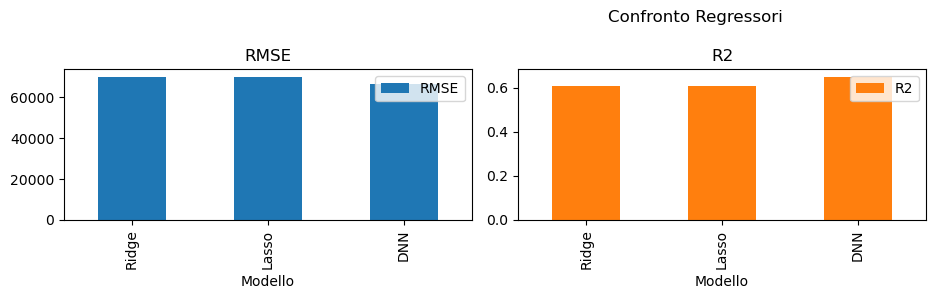

  Modello          RMSE        R2
0   Ridge  70252.499068  0.609838
1   Lasso  70252.659487  0.609837
2     DNN  66389.373522  0.651568


In [15]:
def evaluate(model, device, test_loader):
    nn_true, nn_pred = [],[]

    model.eval()

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            nn_true.extend(y_batch.cpu().numpy().flatten())
            nn_pred.extend(logits.cpu().numpy().flatten())

    return nn_true, nn_pred

nn_true,nn_pred = evaluate(model,device,test_loader)

rmse_nn_test = root_mean_squared_error(nn_true, nn_pred)

r2_nn_test = r2_score(nn_true, nn_pred)

results = pd.DataFrame({
    "Modello" : ["Ridge", "Lasso", "DNN"],
    "RMSE" : [rmse_ridge_test, rmse_lasso_test, rmse_nn_test],
    "R2" : [r2_ridge_test, r2_lasso_test, r2_nn_test]
})

import matplotlib.pyplot as plt

results.plot(kind='bar',subplots=True ,x="Modello", sharex=True, layout=(1,3), figsize=(14,3), title="Confronto Regressori")
plt.tight_layout()
plt.show()
print(results)
